# Praktikum Seismik Refraksi: Metode Intercept Time

| | |
|---|---|
| **Nama** | Muhammad Fikri Aliyuddin |
| **NIM** | H061241051 |
| **Kelas** | C |
| **Tugas** | Project 3 – Artificial Intelligence |

---

Halo semuanya! Di sesi kali ini, kita bakal memodelkan dan menganalisis struktur bawah permukaan dangkal menggunakan **Metode Intercept Time**. Kita akan mensimulasikan model 2 lapisan: misalnya lapisan tanah lapuk (*weathered layer*) di bagian atas, dan lapisan batuan dasar (*bedrock*) yang keras di bawahnya.

**Alur kerja notebook ini (ringkasnya):**
1. Membuat data waktu tempuh gelombang (data sintetis) + noise → *seolah-olah* data lapangan.
2. Memisahkan data menjadi dua segmen (gelombang langsung & gelombang refraksi).
3. Mencari kecepatan ($V_1$, $V_2$) dan ketebalan lapisan ($Z$) dengan regresi linear.
4. Membandingkan hasil dengan nilai sebenarnya, lalu mengecek seberapa besar pengaruh noise.

## 1. Konsep Dasar & Asumsi

Sebelum mulai *ngoding*, kita harus paham dulu logikanya:
*   **Gelombang Langsung (Direct Wave):** Gelombang yang menjalar lurus di dekat permukaan dari sumber (*shot*) ke *geophone* melewati lapisan pertama saja.
*   **Gelombang Refraksi (Kritis):** Gelombang yang turun mengenai batas lapisan, lalu membias dan menjalar sejajar batas lapisan kedua (karena kecepatan di lapisan kedua lebih tinggi), dan energinya "bocor" menjalar naik lagi ke *geophone* di permukaan.

**Asumsi penting dalam metode ini:**
1.  Batas antar lapisan diasumsikan **datar atau horizontal**.
2.  Kecepatan lapisan bawah harus lebih besar dari lapisan atas ($V_2 > V_1$). Kalau enggak, gelombang bias kritis nggak akan pernah terbentuk (ingat prinsip Hukum Snellius!).
3.  Tiap lapisan **homogen** (kecepatan seragam di dalam lapisan).

**Simbol & Satuan yang kita pakai:**
*   $x$ = Jarak geophone / Offset (meter)
*   $t$ = Waktu tempuh atau *Travel time* (sekon atau milisekon)
*   $V_1, V_2$ = Kecepatan gelombang lapisan 1 dan 2 (m/s)
*   $Z$ = Kedalaman / ketebalan lapisan pertama (meter)
*   $t_i$ = *Intercept time* (waktu potong pada sumbu Y saat offset $x = 0$)
*   $x_c$ = *Crossover distance* (jarak di mana gelombang refraksi mulai tiba lebih dulu daripada gelombang langsung)

### Kenapa gelombang refraksi bisa "menjalar di batas lapisan"?
Menurut Hukum Snellius, $\frac{\sin i}{V_1} = \frac{\sin r}{V_2}$. Jika sudut datang dinaikkan terus, sudut bias $r$ ikut membesar sampai mencapai $90^\circ$ (gelombang menjalar sejajar batas lapisan). Sudut datang saat itu disebut **sudut kritis**:

$$\sin i_c = \frac{V_1}{V_2}$$

Ini hanya mungkin jika $V_1 < V_2$ (sehingga $\frac{V_1}{V_2} < 1$). Itulah alasan asumsi nomor 2 di atas.

### Rumus-rumus yang dipakai
| Besaran | Rumus | Penjelasan singkat |
|---|---|---|
| Gelombang langsung | $t = \dfrac{x}{V_1}$ | Garis lurus melewati titik (0,0), kemiringan $= 1/V_1$ |
| Gelombang refraksi | $t = \dfrac{x}{V_2} + t_i$ | Garis lurus, kemiringan $= 1/V_2$, memotong sumbu-Y di $t_i$ |
| Intercept time | $t_i = \dfrac{2Z\sqrt{V_2^2 - V_1^2}}{V_1 V_2}$ | Waktu "tambahan" karena gelombang harus turun lalu naik lagi |
| Ketebalan lapisan | $Z = \dfrac{t_i}{2}\dfrac{V_1 V_2}{\sqrt{V_2^2 - V_1^2}}$ | Hasil membalik rumus $t_i$ |
| Crossover distance | $x_c = 2Z\sqrt{\dfrac{V_2+V_1}{V_2-V_1}}$ | Titik patahan kurva T-X |

Kita cuma butuh library matematika dan plot dasar:
*   `numpy` → perhitungan numerik dan regresi (`polyfit`).
*   `matplotlib` → membuat grafik.

Kita juga mengunci `np.random.seed(42)`. Tanpa baris ini, noise acak berbeda setiap kali sel dijalankan, sehingga angka hasil (dan angka yang dibahas di bagian diskusi) ikut berubah-ubah. Dengan *seed* yang sama, hasilnya **bisa direproduksi** oleh siapa pun.

In [1]:
# Kita cuma butuh library matematika dan plot dasar
import numpy as np
import matplotlib.pyplot as plt

# Kunci angka acak supaya hasil sama setiap kali dijalankan (reproducible)
np.random.seed(42)

## 2. Membuat Data Sintetis (Dummy Data)

Biar kerasa kayak data hasil akuisisi lapangan asli, kita akan bikin *dummy data* dengan persamaan kinematika gelombang. 
Lalu, yang paling penting: kita tambahkan **random noise**. Noise ini mensimulasikan ketidakpastian (*uncertainty*) di lapangan, misalnya akibat angin, getaran jalan, atau *error* saat *picking first break*.

**Langkah di sel berikut:**
1. Tentukan nilai sebenarnya ($V_1$, $V_2$, $Z$) → ini "kunci jawaban" yang nanti kita coba temukan kembali.
2. Buat 30 geophone dengan spasi 2 m (offset 2–60 m).
3. Hitung waktu tempuh gelombang langsung dan gelombang refraksi.
4. Ambil yang **lebih cepat** di tiap geophone (`np.minimum`), karena yang direkam alat hanyalah *first break* (gelombang yang tiba pertama).
5. Tambahkan noise normal dengan simpangan baku 1,5 ms.

Intercept time teoritis (ti)   = 38.73 ms
Crossover distance teoritis    = 25.82 m


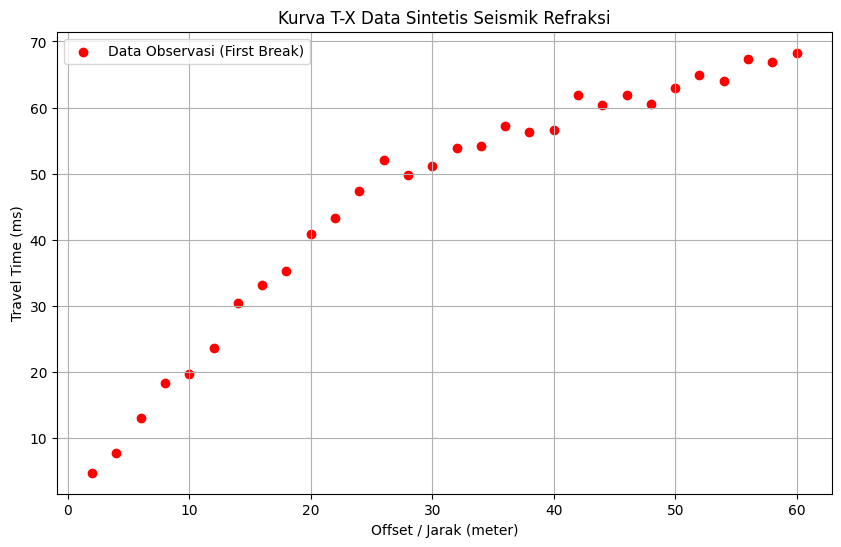

In [2]:
# 1. Tentukan Parameter Sebenarnya (True Values)
V1_true = 500.0  # Kecepatan lapisan 1 dalam m/s (misal tanah lapuk)
V2_true = 2000.0 # Kecepatan lapisan 2 dalam m/s (misal batuan dasar)
Z_true = 10.0    # Kedalaman batuan dasar dalam meter

# 2. Setup Geophone (Offset)
# Pasang geophone dari jarak 2 meter sampai 60 meter, spasi tiap 2 meter
x = np.arange(2, 62, 2)

# 3. Hitung Waktu Tempuh Teoritis (dalam sekon)
# Persamaan gelombang langsung: t = x / V1
t_direct = x / V1_true

# Persamaan gelombang refraksi: t = (x / V2) + ti
# Hitung intercept time (ti) teoritis dulu:
ti_true = (2 * Z_true * np.sqrt(V2_true**2 - V1_true**2)) / (V1_true * V2_true)
t_refract = (x / V2_true) + ti_true

# Crossover distance teoritis (titik patahan kurva T-X)
xc_true = 2 * Z_true * np.sqrt((V2_true + V1_true) / (V2_true - V1_true))

# Waktu tiba pertama (First Break)
# Geophone hanya mendeteksi gelombang mana yang sampai lebih dulu
t_first = np.minimum(t_direct, t_refract)

# 4. Tambahkan Random Noise (Ketidakpastian)
# Kita kasih noise berdistribusi normal sekitar 1.5 ms (0.0015 s)
noise = np.random.normal(0, 0.0015, len(x))
t_obs = t_first + noise

# Kita ubah waktu dari sekon ke milisekon (ms) untuk divisualisasikan
t_obs_ms = t_obs * 1000

print(f"Intercept time teoritis (ti)   = {ti_true*1000:.2f} ms")
print(f"Crossover distance teoritis    = {xc_true:.2f} m")

# 5. Plotting Kurva T-X
plt.figure(figsize=(10, 6))
plt.scatter(x, t_obs_ms, color='red', label='Data Observasi (First Break)')
plt.xlabel('Offset / Jarak (meter)')
plt.ylabel('Travel Time (ms)')
plt.title('Kurva T-X Data Sintetis Seismik Refraksi')
plt.grid(True)
plt.legend()
plt.show()

## 3. Analisis Regresi Linear (Metode Intercept Time)

Dari plot T-X di atas, kita bisa lihat grafiknya patah di satu titik (disebut *crossover distance*). 
*   Garis yang curam di awal adalah **gelombang langsung**. Persamaan garisnya: $t = \frac{1}{V_1}x$
*   Garis yang melandai setelahnya adalah **gelombang refraksi**. Persamaan garisnya: $t = \frac{1}{V_2}x + t_i$

Karena persamaannya mirip dengan persamaan garis lurus biasa ($y = mx + c$), kita bisa lakukan **regresi linear**. 
*   Kemiringan (*slope* atau $m$) adalah kebalikan dari kecepatan: $V = \frac{1}{m}$
*   Waktu potong (*intercept* atau $c$) pada gelombang refraksi adalah $t_i$.

Kita akan memisahkan data sebelum patahan dan sesudah patahan secara manual, lalu melakukan fitting garis.

**Catatan pemilihan segmen:**
*   Patahan terlihat di sekitar 25–26 m, jadi gelombang langsung kita ambil dari offset $< 25$ m, dan gelombang refraksi dari offset $> 30$ m.
*   Titik di antara keduanya (sekitar patahan) sengaja **dibuang** karena di sana kedua gelombang tiba hampir bersamaan, sehingga mudah salah dikelompokkan.
*   Untuk gelombang langsung, secara fisika $t = 0$ saat $x = 0$ (gelombang tidak butuh waktu untuk menempuh jarak nol). Maka garisnya **dipaksa melewati titik (0,0)**. Ini membuat estimasi $V_1$ lebih stabil dibanding membiarkan intercept bebas, terutama karena titik gelombang langsung hanya sedikit (12 titik).

=== HASIL PENGOLAHAN DATA ===
Kecepatan Lapisan 1 (V1) = 496.17 m/s
Kecepatan Lapisan 2 (V2) = 1967.81 m/s
Intercept Time (ti)      = 37.77 ms
Ketebalan Lapisan 1 (Z)  = 9.68 meter
Crossover Distance (xc)  = 25.06 meter



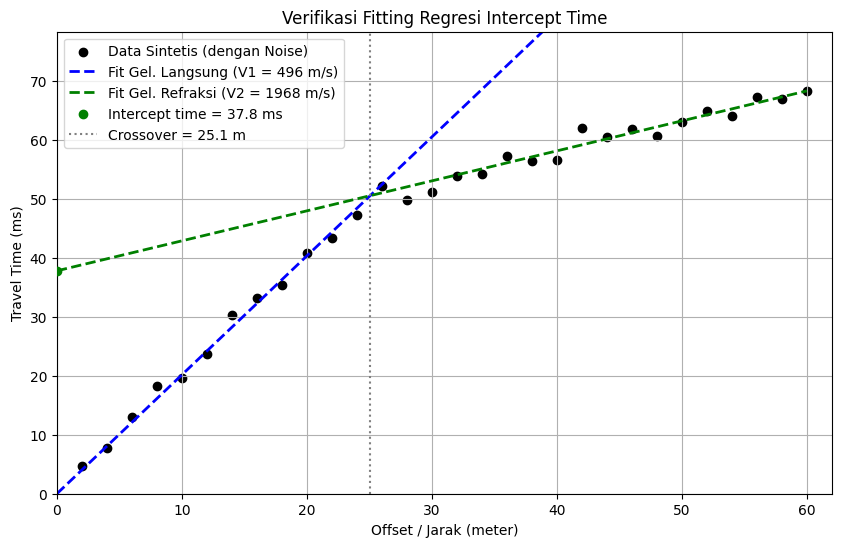

In [3]:
# Dari grafik sebelumnya, patahan terjadi di sekitar jarak 25 meter.
# Kita filter datanya:
mask_direct = x < 25    # Segmen 1: Gelombang Langsung
mask_refract = x > 30   # Segmen 2: Gelombang Refraksi (kita ambil >30m biar aman dari area patahan)

x_direct = x[mask_direct]
t_direct_obs = t_obs[mask_direct]  # Pakai waktu dalam sekon untuk hitungan

x_refract = x[mask_refract]
t_refract_obs = t_obs[mask_refract]

# --- Regresi Gelombang Langsung: t = m1 * x (dipaksa lewat titik asal) ---
# Solusi kuadrat terkecil untuk garis lewat (0,0): m1 = sum(x*t) / sum(x^2)
m1 = np.sum(x_direct * t_direct_obs) / np.sum(x_direct**2)
c1 = 0.0

# --- Regresi Gelombang Refraksi: t = m2 * x + c2 (intercept bebas) ---
# polyfit mereturn [slope (m), intercept (c)]
m2, c2 = np.polyfit(x_refract, t_refract_obs, 1)

# 1. Hitung Kecepatan
V1_calc = 1 / m1
V2_calc = 1 / m2

# Cek syarat fisika: V2 harus > V1, kalau tidak rumus Z tidak valid
assert V2_calc > V1_calc, "V2 <= V1: syarat gelombang refraksi tidak terpenuhi!"

# 2. Hitung Ketebalan Lapisan (Z)
ti_calc = c2  # intercept time dari regresi gelombang refraksi
Z_calc = (ti_calc / 2) * (V1_calc * V2_calc) / np.sqrt(V2_calc**2 - V1_calc**2)

# 3. Hitung Crossover Distance dari hasil regresi (titik potong dua garis)
#    m1*x = m2*x + c2  ->  x = c2 / (m1 - m2)
xc_calc = ti_calc / (m1 - m2)

# Tampilkan Hasil
print("=== HASIL PENGOLAHAN DATA ===")
print(f"Kecepatan Lapisan 1 (V1) = {V1_calc:.2f} m/s")
print(f"Kecepatan Lapisan 2 (V2) = {V2_calc:.2f} m/s")
print(f"Intercept Time (ti)      = {ti_calc*1000:.2f} ms")
print(f"Ketebalan Lapisan 1 (Z)  = {Z_calc:.2f} meter")
print(f"Crossover Distance (xc)  = {xc_calc:.2f} meter\n")

# Visualisasi Fitting Regresi
plt.figure(figsize=(10, 6))
plt.scatter(x, t_obs_ms, color='black', label='Data Sintetis (dengan Noise)')

# Bikin garis regresi dari offset 0 untuk membuktikan intercept time-nya
x_line = np.linspace(0, 60, 100)
t1_line = (m1 * x_line + c1) * 1000  # kali 1000 jadi ms
t2_line = (m2 * x_line + c2) * 1000

plt.plot(x_line, t1_line, 'b--', linewidth=2, label=f'Fit Gel. Langsung (V1 = {V1_calc:.0f} m/s)')
plt.plot(x_line, t2_line, 'g--', linewidth=2, label=f'Fit Gel. Refraksi (V2 = {V2_calc:.0f} m/s)')
plt.scatter([0], [ti_calc*1000], color='green', zorder=5, label=f'Intercept time = {ti_calc*1000:.1f} ms')
plt.axvline(xc_calc, color='gray', linestyle=':', label=f'Crossover = {xc_calc:.1f} m')

# Batasi tampilan grafik agar fokus
plt.xlim(0, 62)
plt.ylim(0, max(t_obs_ms) + 10)
plt.xlabel('Offset / Jarak (meter)')
plt.ylabel('Travel Time (ms)')
plt.title('Verifikasi Fitting Regresi Intercept Time')
plt.legend()
plt.grid(True)
plt.show()

## 4. Evaluasi: Seberapa Dekat Hasilnya dengan Nilai Sebenarnya?

Karena ini data sintetis, kita **punya kunci jawaban** (nilai *true*). Jadi kita bisa menghitung *error* relatif:

$$\text{Error (\%)} = \frac{|\text{hasil hitung} - \text{nilai sebenarnya}|}{\text{nilai sebenarnya}} \times 100\%$$

Kita juga hitung **RMS residual**, yaitu rata-rata "jarak" titik data ke garis regresinya. Kalau RMS residual mendekati besar noise yang kita pasang (1,5 ms), berarti garis regresi sudah menangkap pola data dengan baik; sisanya murni noise yang memang tidak bisa dijelaskan oleh model.

In [4]:
def rms_ms(y_obs, y_fit):
    """RMS residual dalam milisekon."""
    return np.sqrt(np.mean((y_obs - y_fit)**2)) * 1000

rms_direct = rms_ms(t_direct_obs, m1 * x_direct + c1)
rms_refract = rms_ms(t_refract_obs, m2 * x_refract + c2)

def err(calc, true):
    return abs(calc - true) / true * 100

print(f"{'Parameter':<22}{'Sebenarnya':>12}{'Hasil Hitung':>15}{'Error (%)':>11}")
print("-" * 60)
print(f"{'V1 (m/s)':<22}{V1_true:>12.2f}{V1_calc:>15.2f}{err(V1_calc, V1_true):>11.2f}")
print(f"{'V2 (m/s)':<22}{V2_true:>12.2f}{V2_calc:>15.2f}{err(V2_calc, V2_true):>11.2f}")
print(f"{'ti (ms)':<22}{ti_true*1000:>12.2f}{ti_calc*1000:>15.2f}{err(ti_calc, ti_true):>11.2f}")
print(f"{'Z (m)':<22}{Z_true:>12.2f}{Z_calc:>15.2f}{err(Z_calc, Z_true):>11.2f}")
print(f"{'xc (m)':<22}{xc_true:>12.2f}{xc_calc:>15.2f}{err(xc_calc, xc_true):>11.2f}")
print()
print(f"RMS residual gel. langsung = {rms_direct:.2f} ms")
print(f"RMS residual gel. refraksi = {rms_refract:.2f} ms")
print("(Besar noise yang kita pasang = 1.50 ms)")

# Cross-check: Z juga bisa dihitung dari crossover distance
Z_from_xc = (xc_calc / 2) * np.sqrt((V2_calc - V1_calc) / (V2_calc + V1_calc))
print(f"\nCross-check Z dari crossover distance = {Z_from_xc:.2f} m (harus sama dengan Z dari ti)")

Parameter               Sebenarnya   Hasil Hitung  Error (%)
------------------------------------------------------------
V1 (m/s)                    500.00         496.17       0.77
V2 (m/s)                   2000.00        1967.81       1.61
ti (ms)                      38.73          37.77       2.47
Z (m)                        10.00           9.68       3.16
xc (m)                       25.82          25.06       2.94

RMS residual gel. langsung = 1.13 ms
RMS residual gel. refraksi = 1.13 ms
(Besar noise yang kita pasang = 1.50 ms)

Cross-check Z dari crossover distance = 9.68 m (harus sama dengan Z dari ti)


## 5. Seberapa Besar Pengaruh Noise? (Simulasi Berulang)

Satu kali eksperimen hanya memberi **satu** kemungkinan hasil. Supaya kita paham betapa noise bisa menggeser hasil, kita ulangi seluruh prosedur (buat data → regresi → hitung $V_1, V_2, Z$) sebanyak **500 kali** dengan noise acak yang berbeda-beda, lalu lihat sebarannya.

Ini mirip dengan situasi di lapangan: kalau kita mengulang pengukuran, *picking first break* tidak akan persis sama setiap kali.

Jumlah simulasi valid: 500 dari 500

V1: rata-rata =   499.92 m/s | simpangan baku =   7.25 m/s | rentang 95% = [485.52, 514.33] | nilai sebenarnya = 500.0
V2: rata-rata =  2036.90 m/s | simpangan baku = 190.59 m/s | rentang 95% = [1732.95, 2465.53] | nilai sebenarnya = 2000.0
Z: rata-rata =    10.05 m | simpangan baku =   0.51 m | rentang 95% = [9.03, 10.99] | nilai sebenarnya = 10.0


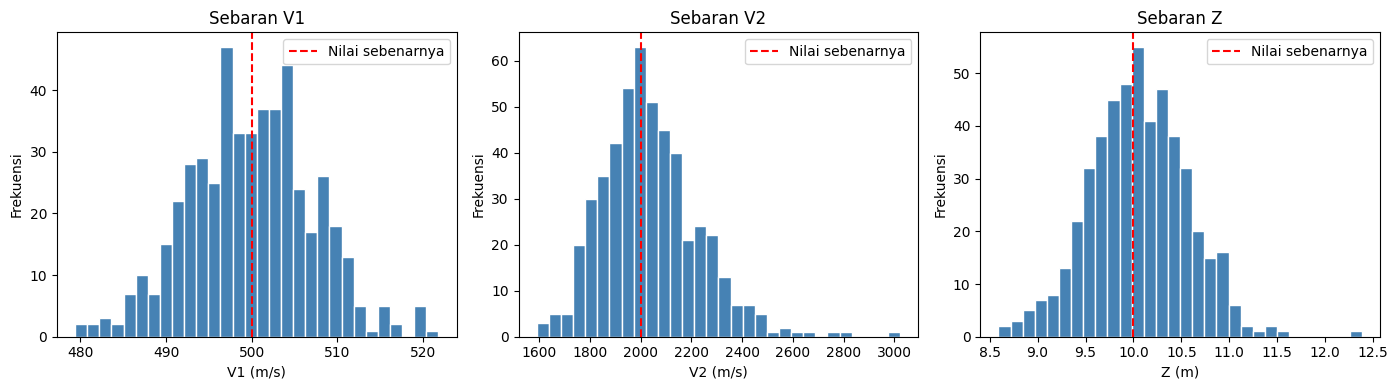

In [5]:
rng = np.random.default_rng(123)   # generator acak terpisah, agar tidak mengganggu seed di atas
n_ulang = 500
hasil = {"V1": [], "V2": [], "Z": []}

for _ in range(n_ulang):
    t_sim = t_first + rng.normal(0, 0.0015, len(x))

    a1 = np.sum(x[mask_direct] * t_sim[mask_direct]) / np.sum(x[mask_direct]**2)
    a2, b2 = np.polyfit(x[mask_refract], t_sim[mask_refract], 1)

    v1, v2 = 1 / a1, 1 / a2
    if v2 <= v1:          # lewati kasus tidak valid (praktis tidak terjadi di sini)
        continue
    z = (b2 / 2) * v1 * v2 / np.sqrt(v2**2 - v1**2)

    hasil["V1"].append(v1); hasil["V2"].append(v2); hasil["Z"].append(z)

for k in hasil:
    hasil[k] = np.array(hasil[k])

print(f"Jumlah simulasi valid: {len(hasil['Z'])} dari {n_ulang}\n")
for nama, true_val, sat in [("V1", V1_true, "m/s"), ("V2", V2_true, "m/s"), ("Z", Z_true, "m")]:
    d = hasil[nama]
    print(f"{nama}: rata-rata = {d.mean():8.2f} {sat} | simpangan baku = {d.std():6.2f} {sat} "
          f"| rentang 95% = [{np.percentile(d, 2.5):.2f}, {np.percentile(d, 97.5):.2f}] | nilai sebenarnya = {true_val}")

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nama, true_val, sat) in zip(axs, [("V1", V1_true, "m/s"), ("V2", V2_true, "m/s"), ("Z", Z_true, "m")]):
    ax.hist(hasil[nama], bins=30, color='steelblue', edgecolor='white')
    ax.axvline(true_val, color='red', linestyle='--', label='Nilai sebenarnya')
    ax.set_xlabel(f'{nama} ({sat})')
    ax.set_ylabel('Frekuensi')
    ax.set_title(f'Sebaran {nama}')
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Diskusi dan Verifikasi Fisika

Coba kita evaluasi hasil dari perhitungan algoritma di atas (angka di bawah berasal dari eksekusi dengan `seed = 42`):

1. **Verifikasi Syarat Refraksi:** 
   * Kecepatan $V_2$ ($\approx$ 1968 m/s) jelas **lebih besar** daripada $V_1$ ($\approx$ 496 m/s), rasionya sekitar 4 kali lipat. Ini sesuai syarat $V_2 > V_1$: perambatan gelombang kritis hanya terjadi kalau ada lapisan yang lebih padat/keras di bawahnya.
   * Sudut kritisnya: $i_c = \arcsin(V_1/V_2) \approx \arcsin(0{,}25) \approx 14{,}5^\circ$.

2. **Bukti Visual dari Plot:** 
   * Garis regresi biru (*direct wave*) dan hijau (*refracted wave*) terlihat **mengikuti sebaran titik data (titik hitam)** dengan baik. Titik yang menyimpang hanya sekitar 1–2 ms dari garis, wajar karena kita memasang noise 1,5 ms.
   * Perhatikan garis hijau putus-putus. Kalau ditarik mundur sampai jarak $x = 0$, garis ini tidak berawal dari angka nol, melainkan memotong sumbu-Y di sekitar **37,8 ms** (nilai teoritisnya 38,7 ms). Inilah bukti visual kemunculan **Intercept Time ($t_i$)**. Fisikanya: gelombang refraksi harus "turun ke batas lapisan" dan "naik kembali" dulu, jadi ada waktu tambahan yang tidak dipakai untuk menempuh jarak horizontal.
   * Garis biru dan hijau berpotongan di sekitar **25 m** (*crossover distance*; teoritis 25,8 m). Sebelum titik ini gelombang langsung tiba lebih dulu, sesudahnya gelombang refraksi yang menang karena lajunya jauh lebih tinggi.

3. **Akurasi Hasil (Tabel di Bagian 4):** 
   * Semua parameter meleset kurang dari 3,2%: $V_1$ ≈ 0,8%, $V_2$ ≈ 1,6%, $Z$ ≈ 9,68 m dari 10 m (≈ 3,2%).
   * RMS residual (≈ 1,1 ms) berada di kisaran besar noise yang kita pasang (1,5 ms). Artinya garis regresi sudah menangkap pola data; sisa selisihnya murni noise acak.
   * Nilai $Z$ yang dihitung lewat $t_i$ dan lewat $x_c$ sama persis. Ini wajar karena keduanya berasal dari dua garis regresi yang sama (hanya pemeriksaan konsistensi rumus, bukan bukti independen).

4. **Pengaruh Noise (Uncertainty), dari simulasi 500 kali:** 
   * $V_1$ sangat stabil (simpangan baku ≈ 7 m/s), karena ditentukan oleh titik-titik dekat sumber yang waktunya kecil dan kemiringannya curam.
   * $V_2$ jauh **lebih sensitif** (simpangan baku ≈ 190 m/s, rentang 95% sekitar 1730–2470 m/s). Sebabnya, kemiringan garis refraksi sangat landai (1/2000 s/m), sehingga selisih kecil pada waktu tempuh langsung mengubah kemiringan, dan kecepatan = 1/kemiringan jadi berubah besar.
   * $Z$ rata-rata mendekati nilai sebenarnya (≈ 10,05 m), dengan rentang 95% sekitar 9,0–11,0 m. Jadi di satu kali pengukuran, hasil $Z$ bisa meleset sekitar ±1 m hanya karena noise.
   * Pelajaran praktisnya: di lapangan, keakuratan metode ini sangat bergantung pada kualitas *picking first break*, jumlah geophone di segmen refraksi, dan ketenangan lapangan saat akuisisi. Menambah jumlah geophone atau memperpanjang bentangan akan menurunkan ketidakpastian $V_2$.

5. **Keterbatasan Metode:** 
   * Hanya berlaku untuk model **2 lapisan dengan batas datar**. Kalau batas miring, perlu *shot* maju dan mundur (*forward–reverse*).
   * Tidak bisa mendeteksi **lapisan tersembunyi (*hidden layer*)** atau **lapisan dengan kecepatan lebih rendah di bawah lapisan cepat (*velocity inversion*)**, karena gelombang dari lapisan seperti itu tidak pernah menjadi *first break*.
   * Pemisahan segmen (25 m dan 30 m) di sini dilakukan manual berdasarkan grafik; untuk data nyata, pemilihan ini subjektif dan memengaruhi hasil.

**Kesimpulan:** Metode *Intercept Time* berhasil memulihkan parameter model ($V_1 \approx 496$ m/s, $V_2 \approx 1968$ m/s, $Z \approx 9{,}7$ m) yang dekat dengan nilai sebenarnya (500 m/s, 2000 m/s, 10 m). Hasil tidak pernah persis sama karena noise, dan $V_2$ adalah parameter yang paling rentan terhadap noise.